# Mushroom CNN and RNN Classification + Hugging Face NLP Tokenization

**Course:** AIP301 &nbsp;|&nbsp; **Environment:** Python, TensorFlow/Keras, Hugging Face Transformers

This notebook builds, trains, evaluates and compares a **Convolutional Neural Network (CNN)** and a
**Recurrent Neural Network (RNN)** on the Mushroom Classification dataset, and then tokenizes a text
passage using a pretrained **Hugging Face** tokenizer.

## 1. Objective

1. Load and explore the Mushroom dataset.
2. Preprocess the categorical data (encoding, 70/30 train/test split) without data leakage.
3. Build and train a **CNN** (Adam optimizer, batch size 30, 10 epochs).
4. Build and train an **RNN** (RMSprop optimizer, batch size 40, 20 epochs).
5. Evaluate both models with test accuracy, predictions, confusion matrices and classification reports.
6. Compare the two models and recommend the better one **based on measured test accuracy**.
7. **Generative AI / NLP task:** load `exercise_text.json` and tokenize its text with a Hugging Face tokenizer.

> **Note:** Every number in this notebook is produced by running the code. No results are typed in by hand.

## 2. Import Libraries

We import the data-science stack (NumPy, pandas, matplotlib, seaborn, scikit-learn), **TensorFlow/Keras**
for the neural networks and **Hugging Face Transformers** for tokenization.

Random seeds are fixed (`42`) so the results are as reproducible as possible.
Neural-network training can still vary slightly between machines, operating systems, CPU/GPU hardware
and TensorFlow versions.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"            # hide TensorFlow info messages
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"    # cleaner output when the tokenizer downloads

import json
import subprocess
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")   # hide non-critical TensorFlow warnings (e.g. "no GPU on Windows")

# ---- Reproducibility --------------------------------------------------------
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)   # sets Python, NumPy and TensorFlow seeds
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# ---- Display / plotting settings --------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

COLOR_1 = "#2a78d6"   # blue   (training / CNN)
COLOR_2 = "#eb6834"   # orange (validation / RNN)
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
})

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)

Python      : 3.13.11
NumPy       : 2.5.3
pandas      : 3.0.6
TensorFlow  : 2.21.0
Keras       : 3.15.1


## 3. Download / Verify Dataset

The notebook first locates the project folder and checks that both data files exist in `data/`.
If a file is missing, it runs `download_data.py` to download it automatically.
If the download also fails, a clear error message explains where to place the files manually.

In [2]:
def find_project_root(start: Path) -> Path:
    """Walk up from `start` until the folder containing download_data.py is found."""
    for folder in [start, *start.parents]:
        if (folder / "download_data.py").exists():
            return folder
    return start

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR     = PROJECT_ROOT / "data"
FIGURES_DIR  = PROJECT_ROOT / "outputs" / "figures"
REPORTS_DIR  = PROJECT_ROOT / "outputs" / "reports"
MODELS_DIR   = PROJECT_ROOT / "outputs" / "models"
for folder in (DATA_DIR, FIGURES_DIR, REPORTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

MUSHROOM_CSV = DATA_DIR / "mushrooms.csv"
TEXT_JSON    = DATA_DIR / "exercise_text.json"
REQUIRED_FILES = [MUSHROOM_CSV, TEXT_JSON]

def files_ok():
    return all(f.is_file() and f.stat().st_size > 0 for f in REQUIRED_FILES)

if not files_ok():
    print("One or more data files are missing. Running download_data.py ...\n")
    result = subprocess.run([sys.executable, str(PROJECT_ROOT / "download_data.py")],
                            capture_output=True, text=True)
    print(result.stdout, result.stderr)

if not files_ok():
    missing = [str(f.relative_to(PROJECT_ROOT)) for f in REQUIRED_FILES
               if not (f.is_file() and f.stat().st_size > 0)]
    raise FileNotFoundError(
        "Required data file(s) not found: " + ", ".join(missing) + "\n"
        "Please download them manually and place them in the data/ folder:\n"
        "  https://lms.digiskills.pk/Courses/AIP301/Downloads/mushrooms.csv      -> data/mushrooms.csv\n"
        "  https://lms.digiskills.pk/Courses/AIP301/Downloads/exercise_text.json -> data/exercise_text.json"
    )

print("Project root:", PROJECT_ROOT)
for f in REQUIRED_FILES:
    print(f"  [OK] {f.relative_to(PROJECT_ROOT)}  ({f.stat().st_size:,} bytes)")

Project root: D:\CProjects\mushroom-cnn-rnn-classification
  [OK] data\mushrooms.csv  (374,003 bytes)
  [OK] data\exercise_text.json  (858 bytes)


## 4. Load Mushroom Dataset

The CSV file is loaded with pandas. Every column is read as text (`dtype=str`) because the values are
single-letter category codes.

In [3]:
df = pd.read_csv(MUSHROOM_CSV, dtype=str)
df.columns = df.columns.str.strip()

print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


## 5. Dataset Exploration

### 5.1 Column names and data types

In [4]:
print("Column names:")
print(list(df.columns))
print()
print("Data types:")
print(df.dtypes.value_counts().rename("number of columns"))
df.info()

Column names:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Data types:
str    23
Name: number of columns, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124

### 5.2 Missing values

In [5]:
missing_counts = df.isna().sum()
print("Total missing (NaN) values:", int(missing_counts.sum()))

# In this dataset a '?' character may be used to mark an unknown value
question_marks = (df == "?").sum()
question_marks = question_marks[question_marks > 0]
if len(question_marks):
    print("\nColumns that contain '?' (unknown) values:")
    print(question_marks.to_string())
else:
    print("No '?' placeholder values found.")

Total missing (NaN) values: 0

Columns that contain '?' (unknown) values:
stalk-root    2480


**Interpretation:** Any `?` values mark an *unknown* attribute value. Instead of deleting those rows,
we keep `?` as its own category, so the network can learn whether "unknown" carries information.

### 5.3 Basic descriptive information

In [6]:
# For categorical data, describe() shows the count, number of unique values,
# the most frequent value (top) and how often it occurs (freq)
df.describe().T

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


### 5.4 Identify the target column

The target column is detected automatically instead of being assumed.
We look for a common target name (`class`, `target`, `label`, ...). If none is found,
the last column is used. A warning is printed in that case so it can be checked.

In [7]:
TARGET_CANDIDATES = ["class", "classes", "target", "label", "labels", "y", "edibility", "edible"]

lower_to_original = {c.lower(): c for c in df.columns}
TARGET_COL = next((lower_to_original[name] for name in TARGET_CANDIDATES if name in lower_to_original), None)
if TARGET_COL is None:
    TARGET_COL = df.columns[-1]
    print(f"WARNING: no standard target column name found - using the last column '{TARGET_COL}'.")

print("Target column:", TARGET_COL)
print("Target values:", sorted(df[TARGET_COL].unique()))

Target column: class
Target values: ['e', 'p']


### 5.5 Class distribution

,class,count,percentage
0,edible (e),4208,51.8
1,poisonous (p),3916,48.2


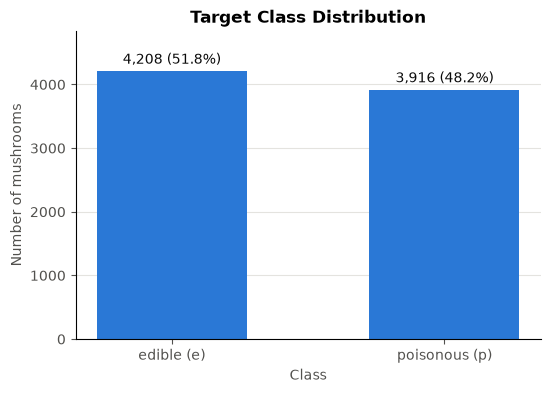

In [8]:
# Readable names for the standard mushroom class codes (used only if the codes match)
CLASS_NAME_MAP = {"e": "edible", "p": "poisonous"}
class_codes = sorted(df[TARGET_COL].unique())
use_names = set(class_codes) <= set(CLASS_NAME_MAP)

def readable(code_value):
    return f"{CLASS_NAME_MAP[code_value]} ({code_value})" if use_names else str(code_value)

class_counts = df[TARGET_COL].value_counts().sort_index()
class_table = pd.DataFrame({
    "class": [readable(c) for c in class_counts.index],
    "count": class_counts.values,
    "percentage": (class_counts.values / class_counts.sum() * 100).round(2),
})
display(class_table)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_table["class"], class_table["count"], color=COLOR_1, width=0.55)
ax.bar_label(bars, labels=[f"{c:,} ({p:.1f}%)" for c, p in zip(class_table["count"], class_table["percentage"])],
             padding=3, color="#0b0b0b")
ax.set_title("Target Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of mushrooms")
ax.grid(axis="x", visible=False)
ax.margins(y=0.15)
plt.savefig(FIGURES_DIR / "class_distribution.png")
plt.show()

**Interpretation:** The table and bar chart show how many samples belong to each class.
If the classes are roughly balanced, accuracy is a fair headline metric. Precision, recall and F1-score
are still reported later for a fuller picture.

### 5.6 Unique values of the categorical columns

In [9]:
unique_summary = pd.DataFrame({
    "n_unique": df.nunique(),
    "unique_values": df.apply(lambda col: ", ".join(sorted(col.dropna().unique()))),
})
unique_summary

,n_unique,unique_values
class,2,"e, p"
cap-shape,6,"b, c, f, k, s, x"
cap-surface,4,"f, g, s, y"
cap-color,10,"b, c, e, g, n, p, r, u, w, y"
bruises,2,"f, t"
odor,9,"a, c, f, l, m, n, p, s, y"
gill-attachment,2,"a, f"
gill-spacing,2,"c, w"
gill-size,2,"b, n"
gill-color,12,"b, e, g, h, k, n, o, p, r, u, w, y"


In [10]:
constant_cols = [c for c in df.columns if df[c].nunique() <= 1]
print("Columns with only one unique value (they carry no information):", constant_cols or "none")

Columns with only one unique value (they carry no information): ['veil-type']


## 6. Data Preprocessing

### Why must categorical data be converted to numbers?

Neural networks are built from mathematical operations: weighted sums, matrix multiplications,
activation functions and gradient-based optimization. These operations only work on **numbers**.
Letters such as `x`, `f` or `p` cannot be multiplied by a weight, so every category must be converted
to a numerical form first.

* **Features (X) - One-Hot Encoding:** each categorical column becomes several 0/1 columns, one per category.
  This avoids giving the categories a false order (for example `a=0, b=1, c=2` would wrongly suggest `c > b > a`).
* **Target (y) - Label Encoding:** class labels are mapped to integers (`0, 1, ...`), which is the
  format expected by the Keras loss functions.

### Avoiding data leakage

The data is **split first**, and the encoders are then **fitted on the training set only**.
The test set is transformed with the already-fitted encoders, so no information about the test data
influences preprocessing. Categories that appear only in the test set are safely ignored
(`handle_unknown="ignore"`).

### 6.1 Separate features (X) and target (y)

In [11]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

print("Features X shape:", X.shape)
print("Target   y shape:", y.shape)

Features X shape: (8124, 22)
Target   y shape: (8124,)


## 7. Train/Test Split

The data is split into exactly **70% training** and **30% testing** with `random_state=42`.
`stratify=y` keeps the same class proportions in both sets.

In [12]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

print(f"Training samples: {len(X_train_raw):,} ({len(X_train_raw) / len(X):.0%})")
print(f"Testing samples : {len(X_test_raw):,} ({len(X_test_raw) / len(X):.0%})")
print()
print("Class proportions (train vs test):")
display(pd.DataFrame({
    "train": y_train_raw.value_counts(normalize=True).round(4),
    "test":  y_test_raw.value_counts(normalize=True).round(4),
}))

Training samples: 5,686 (70%)
Testing samples : 2,438 (30%)

Class proportions (train vs test):


,train,test
class,,
e,0.5179,0.518
p,0.4821,0.482


### 7.1 Encode the features and the target (fitted on the training data only)

In [13]:
# Drop columns that are constant in the TRAINING data (they cannot help classification)
constant_in_train = [c for c in X_train_raw.columns if X_train_raw[c].nunique() <= 1]
X_train_raw = X_train_raw.drop(columns=constant_in_train)
X_test_raw  = X_test_raw.drop(columns=constant_in_train)
print("Dropped constant column(s):", constant_in_train or "none")

# ---- One-Hot Encoding of the input features ----
feature_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
X_train_encoded = feature_encoder.fit_transform(X_train_raw)   # fit on training data only
X_test_encoded  = feature_encoder.transform(X_test_raw)        # only transform the test data

# ---- Label Encoding of the target ----
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)
y_test  = label_encoder.transform(y_test_raw)

CLASS_LABELS = [readable(c) for c in label_encoder.classes_]
NUM_CLASSES  = len(label_encoder.classes_)

print("Original categorical feature columns:", X_train_raw.shape[1])
print("One-hot encoded feature columns     :", X_train_encoded.shape[1])
print()
print("Target encoding:")
for idx, label in enumerate(CLASS_LABELS):
    print(f"  {idx} -> {label}")
print("Number of target classes:", NUM_CLASSES)

Dropped constant column(s): ['veil-type']
Original categorical feature columns: 21
One-hot encoded feature columns     : 116

Target encoding:
  0 -> edible (e)
  1 -> poisonous (p)
Number of target classes: 2


### 7.2 Reshape the data to 3D for the CNN and RNN

`Conv1D` and `SimpleRNN` layers expect 3D input: **(samples, steps, channels)**.
Each encoded feature is treated as one step of a sequence with a single channel:

`(samples, number_of_features, 1)`

In [14]:
NUM_FEATURES = X_train_encoded.shape[1]

X_train = X_train_encoded.reshape(-1, NUM_FEATURES, 1)
X_test  = X_test_encoded.reshape(-1, NUM_FEATURES, 1)

print("X_train shape:", X_train.shape, "-> (samples, number_of_features, 1)")
print("X_test  shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test  shape:", y_test.shape)

X_train shape: (5686, 116, 1) -> (samples, number_of_features, 1)
X_test  shape: (2438, 116, 1)
y_train shape: (5686,)
y_test  shape: (2438,)


### 7.3 Choose the output layer from the actual number of classes

The output layer is **not hard-coded**. It is chosen from the number of target classes found in the data:

| Number of classes | Output layer | Loss function |
|---|---|---|
| 2 (binary) | `Dense(1, activation="sigmoid")` | `binary_crossentropy` |
| more than 2 | `Dense(NUM_CLASSES, activation="softmax")` | `sparse_categorical_crossentropy` |

In [15]:
IS_BINARY = NUM_CLASSES == 2

if IS_BINARY:
    OUTPUT_UNITS, OUTPUT_ACTIVATION, LOSS = 1, "sigmoid", "binary_crossentropy"
else:
    OUTPUT_UNITS, OUTPUT_ACTIVATION, LOSS = NUM_CLASSES, "softmax", "sparse_categorical_crossentropy"

print(f"Classification type : {'binary' if IS_BINARY else 'multi-class'} ({NUM_CLASSES} classes)")
print(f"Output layer        : Dense({OUTPUT_UNITS}, activation='{OUTPUT_ACTIVATION}')")
print(f"Loss function       : {LOSS}")


def predict_classes(model, X_data):
    """Return the predicted class index for every sample."""
    probabilities = model.predict(X_data, verbose=0)
    if IS_BINARY:
        return (probabilities.ravel() >= 0.5).astype(int)
    return probabilities.argmax(axis=1)


def plot_training_history(history, model_name, filename):
    """Plot training vs validation accuracy and loss side by side, and save the figure."""
    hist = history.history
    epochs = range(1, len(hist["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

    for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(epochs, hist[metric], color=COLOR_1, marker="o", markersize=5, label=f"Training {metric}")
        ax.plot(epochs, hist[f"val_{metric}"], color=COLOR_2, marker="o", markersize=5, label=f"Validation {metric}")
        ax.set_title(f"{model_name}: Training vs Validation {title}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.set_xticks(list(epochs))
        ax.legend(frameon=False)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / filename)
    plt.show()


def plot_confusion_matrix(y_true, y_pred, model_name, filename):
    """Draw a labelled confusion matrix heatmap and save it."""
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True, linewidths=2, linecolor="white",
                xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, ax=ax, annot_kws={"size": 12})
    ax.set_title(f"{model_name} Confusion Matrix (Test Set)")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.grid(False)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / filename)
    plt.show()
    return cm


def save_classification_report(y_true, y_pred, model_name, prefix):
    """Print the classification report and save it as .txt and .csv files."""
    report_text = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_LABELS, digits=4, zero_division=0)
    report_dict = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_LABELS, digits=4, zero_division=0,
                                        output_dict=True)
    (REPORTS_DIR / f"{prefix}_classification_report.txt").write_text(
        f"{model_name} Classification Report (Test Set)\n\n{report_text}", encoding="utf-8")
    pd.DataFrame(report_dict).T.round(4).to_csv(REPORTS_DIR / f"{prefix}_classification_report.csv")
    print(f"{model_name} Classification Report (Test Set)\n")
    print(report_text)
    return report_dict

Classification type : binary (2 classes)
Output layer        : Dense(1, activation='sigmoid')
Loss function       : binary_crossentropy


## 8. CNN Model

**Required configuration:** Model = CNN, Batch size = **30**, Epochs = **10**, Optimizer = **Adam**

Architecture:

1. **Input** - `(number_of_features, 1)`
2. **Conv1D** (32 filters, kernel 3, ReLU) - learns local patterns across neighbouring encoded features
3. **MaxPooling1D** - downsamples and keeps the strongest responses
4. **Conv1D** (64 filters, kernel 3, ReLU) - learns higher-level patterns
5. **MaxPooling1D**
6. **Flatten** - converts the feature maps to a vector
7. **Dense** (64, ReLU) - combines the learned features
8. **Dropout** (0.3) - reduces overfitting
9. **Output** - chosen from the number of classes (see section 7.3)

In [16]:
CNN_BATCH_SIZE = 30
CNN_EPOCHS     = 10

keras.utils.set_random_seed(RANDOM_STATE)

cnn_model = keras.Sequential([
    layers.Input(shape=(NUM_FEATURES, 1)),
    layers.Conv1D(filters=32, kernel_size=3, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(filters=64, kernel_size=3, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(OUTPUT_UNITS, activation=OUTPUT_ACTIVATION),
], name="CNN_Mushroom")

cnn_model.compile(optimizer=keras.optimizers.Adam(), loss=LOSS, metrics=["accuracy"])
cnn_model.summary()

Model: "CNN_Mushroom"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 116, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 58, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 58, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 29, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1856)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       118,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 125,249 (489.25 KB)

 Trainable params: 125,249 (489.25 KB)

 Non-trainable params: 0 (0.00 B)

## 9. CNN Training

The CNN is trained for exactly **10 epochs** with **batch size 30**.
`validation_split=0.2` holds back 20% of the *training* data for validation, so the 70/30
train/test split is unchanged and the test set stays unseen until evaluation.

In [17]:
start_time = time.time()
cnn_history = cnn_model.fit(
    X_train, y_train,
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    validation_split=0.2,
    verbose=2,
)
cnn_training_time = time.time() - start_time
print(f"\nCNN training time: {cnn_training_time:.1f} seconds")

cnn_model.save(MODELS_DIR / "cnn_model.keras")
print("Model saved to outputs/models/cnn_model.keras")

Epoch 1/10


152/152 - 2s - 14ms/step - accuracy: 0.9382 - loss: 0.1716 - val_accuracy: 0.9938 - val_loss: 0.0251


Epoch 2/10


152/152 - 1s - 5ms/step - accuracy: 0.9967 - loss: 0.0163 - val_accuracy: 0.9991 - val_loss: 0.0064


Epoch 3/10


...

Epoch 9/10


152/152 - 1s - 5ms/step - accuracy: 1.0000 - loss: 1.7479e-04 - val_accuracy: 1.0000 - val_loss: 2.9388e-04


Epoch 10/10


152/152 - 1s - 6ms/step - accuracy: 1.0000 - loss: 1.6190e-04 - val_accuracy: 1.0000 - val_loss: 2.0107e-04



CNN training time: 9.2 seconds
Model saved to outputs/models/cnn_model.keras


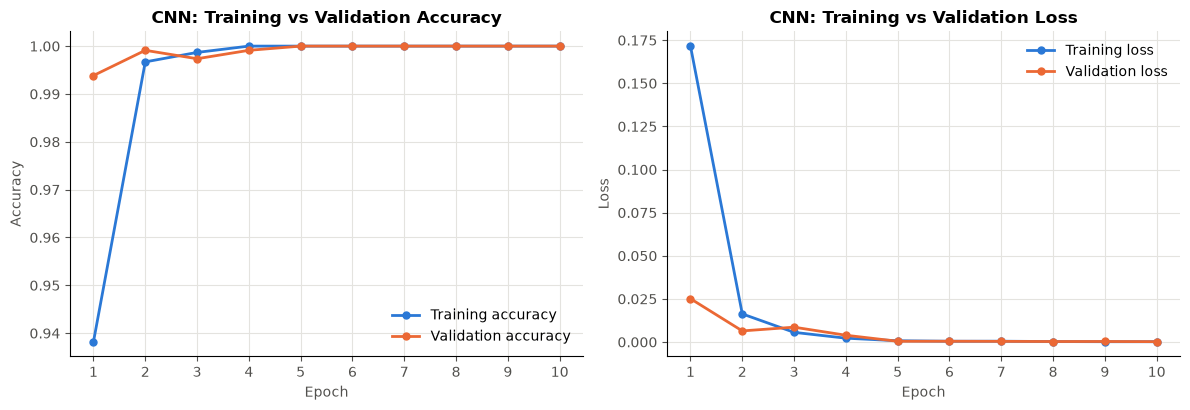

Final epoch - training accuracy: 1.0000, validation accuracy: 1.0000
Final epoch - training loss    : 0.0002, validation loss    : 0.0002


In [18]:
plot_training_history(cnn_history, "CNN", "cnn_training_history.png")

h = cnn_history.history
print(f"Final epoch - training accuracy: {h['accuracy'][-1]:.4f}, validation accuracy: {h['val_accuracy'][-1]:.4f}")
print(f"Final epoch - training loss    : {h['loss'][-1]:.4f}, validation loss    : {h['val_loss'][-1]:.4f}")

**Interpretation:** If the training and validation curves stay close together, the CNN generalizes
well. A growing gap (training accuracy rising while validation accuracy falls) would indicate overfitting.

## 10. CNN Evaluation

The trained CNN is evaluated on the **unseen 30% test set**.

In [19]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(X_test, y_test, verbose=0)
print(f"CNN Test Loss    : {cnn_test_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_test_accuracy:.4f} ({cnn_test_accuracy:.2%})")

CNN Test Loss    : 0.0002
CNN Test Accuracy: 1.0000 (100.00%)


## 11. CNN Predictions

Predicted probabilities are converted to class indices and then back to the original class labels.

In [20]:
cnn_pred = predict_classes(cnn_model, X_test)
cnn_pred_labels = label_encoder.inverse_transform(cnn_pred)

cnn_pred_table = pd.DataFrame({
    "Actual Class":   [readable(c) for c in y_test_raw.values[:10]],
    "CNN Prediction": [readable(c) for c in cnn_pred_labels[:10]],
})
cnn_pred_table["Correct?"] = np.where(cnn_pred_table["Actual Class"] == cnn_pred_table["CNN Prediction"], "Yes", "No")
print("First 10 CNN predictions on the test set:")
display(cnn_pred_table)
print(f"Correct predictions: {(cnn_pred == y_test).sum():,} / {len(y_test):,}")

First 10 CNN predictions on the test set:


,Actual Class,CNN Prediction,Correct?
0,poisonous (p),poisonous (p),Yes
1,poisonous (p),poisonous (p),Yes
2,edible (e),edible (e),Yes
3,poisonous (p),poisonous (p),Yes
4,edible (e),edible (e),Yes
5,poisonous (p),poisonous (p),Yes
6,poisonous (p),poisonous (p),Yes
7,poisonous (p),poisonous (p),Yes
8,poisonous (p),poisonous (p),Yes
9,edible (e),edible (e),Yes


Correct predictions: 2,438 / 2,438


## 12. CNN Confusion Matrix

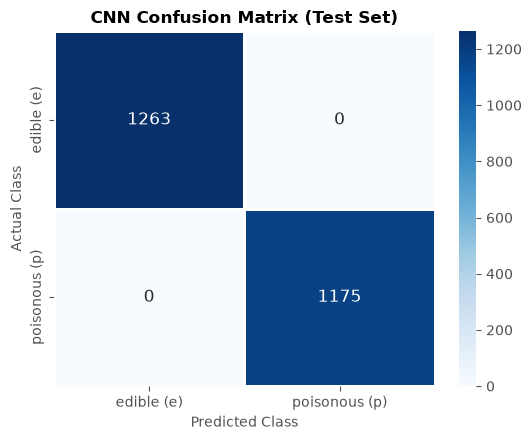

Rows = actual class, columns = predicted class
                       Predicted: edible (e)  Predicted: poisonous (p)
Actual: edible (e)                      1263                         0
Actual: poisonous (p)                      0                      1175


In [21]:
cnn_cm = plot_confusion_matrix(y_test, cnn_pred, "CNN", "cnn_confusion_matrix.png")
print("Rows = actual class, columns = predicted class")
print(pd.DataFrame(cnn_cm, index=[f"Actual: {c}" for c in CLASS_LABELS],
                   columns=[f"Predicted: {c}" for c in CLASS_LABELS]))

**Interpretation:** The diagonal cells are correct predictions. The off-diagonal cells are mistakes.
For mushrooms, a *poisonous* mushroom predicted as *edible* is the most dangerous error.

## 13. CNN Classification Report

In [22]:
cnn_report = save_classification_report(y_test, cnn_pred, "CNN", "cnn")

CNN Classification Report (Test Set)

               precision    recall  f1-score   support

   edible (e)     1.0000    1.0000    1.0000      1263
poisonous (p)     1.0000    1.0000    1.0000      1175

     accuracy                         1.0000      2438
    macro avg     1.0000    1.0000    1.0000      2438
 weighted avg     1.0000    1.0000    1.0000      2438



## 14. RNN Model

**Required configuration:** Model = RNN, Batch size = **40**, Epochs = **20**, Optimizer = **RMSprop**

Architecture:

1. **Input** - `(number_of_features, 1)`: the encoded features are read as a sequence, one value per step
2. **SimpleRNN** (64 units) - processes the sequence step by step and keeps a hidden state (memory)
3. **Dropout** (0.3) - reduces overfitting
4. **Dense** (32, ReLU)
5. **Output** - chosen from the number of classes (see section 7.3)

In [23]:
RNN_BATCH_SIZE = 40
RNN_EPOCHS     = 20

keras.utils.set_random_seed(RANDOM_STATE)

rnn_model = keras.Sequential([
    layers.Input(shape=(NUM_FEATURES, 1)),
    layers.SimpleRNN(64, activation="tanh"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(OUTPUT_UNITS, activation=OUTPUT_ACTIVATION),
], name="RNN_Mushroom")

rnn_model.compile(optimizer=keras.optimizers.RMSprop(), loss=LOSS, metrics=["accuracy"])
rnn_model.summary()

Model: "RNN_Mushroom"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

## 15. RNN Training

The RNN is trained for exactly **20 epochs** with **batch size 40**, using the same
`validation_split=0.2` from the training data.

In [24]:
start_time = time.time()
rnn_history = rnn_model.fit(
    X_train, y_train,
    epochs=RNN_EPOCHS,
    batch_size=RNN_BATCH_SIZE,
    validation_split=0.2,
    verbose=2,
)
rnn_training_time = time.time() - start_time
print(f"\nRNN training time: {rnn_training_time:.1f} seconds")

rnn_model.save(MODELS_DIR / "rnn_model.keras")
print("Model saved to outputs/models/rnn_model.keras")

Epoch 1/20


114/114 - 3s - 24ms/step - accuracy: 0.8663 - loss: 0.3416 - val_accuracy: 0.9060 - val_loss: 0.2613


Epoch 2/20


114/114 - 1s - 12ms/step - accuracy: 0.9217 - loss: 0.2056 - val_accuracy: 0.9350 - val_loss: 0.1696


Epoch 3/20


...

Epoch 19/20


114/114 - 1s - 13ms/step - accuracy: 0.9965 - loss: 0.0118 - val_accuracy: 1.0000 - val_loss: 6.0957e-05


Epoch 20/20


114/114 - 1s - 13ms/step - accuracy: 0.9987 - loss: 0.0053 - val_accuracy: 1.0000 - val_loss: 3.4988e-05



RNN training time: 30.1 seconds
Model saved to outputs/models/rnn_model.keras


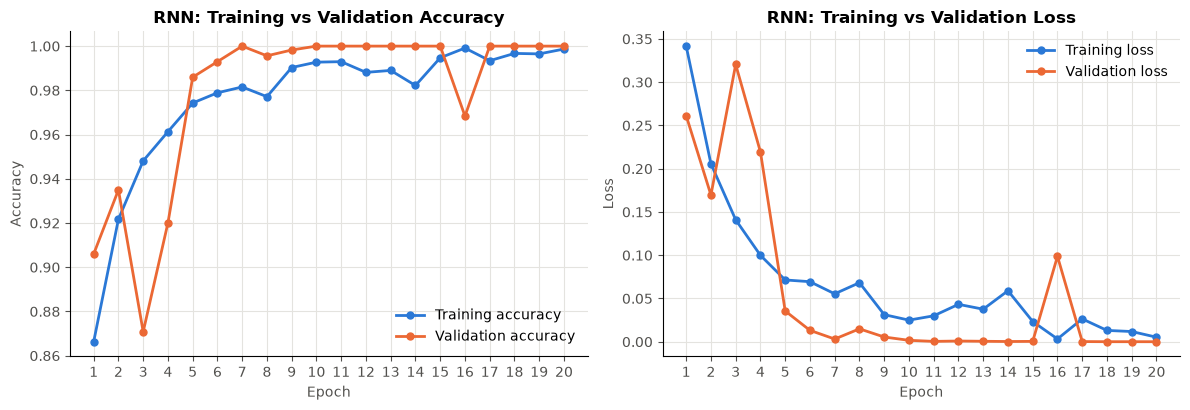

Final epoch - training accuracy: 0.9987, validation accuracy: 1.0000
Final epoch - training loss    : 0.0053, validation loss    : 0.0000


In [25]:
plot_training_history(rnn_history, "RNN", "rnn_training_history.png")

h = rnn_history.history
print(f"Final epoch - training accuracy: {h['accuracy'][-1]:.4f}, validation accuracy: {h['val_accuracy'][-1]:.4f}")
print(f"Final epoch - training loss    : {h['loss'][-1]:.4f}, validation loss    : {h['val_loss'][-1]:.4f}")

**Interpretation:** These curves show how quickly the RNN learns and whether it overfits.
A SimpleRNN reads the one-hot features one step at a time, so it usually needs more epochs than the
CNN to converge.

## 16. RNN Evaluation

In [26]:
rnn_test_loss, rnn_test_accuracy = rnn_model.evaluate(X_test, y_test, verbose=0)
print(f"RNN Test Loss    : {rnn_test_loss:.4f}")
print(f"RNN Test Accuracy: {rnn_test_accuracy:.4f} ({rnn_test_accuracy:.2%})")

RNN Test Loss    : 0.0000
RNN Test Accuracy: 1.0000 (100.00%)


## 17. RNN Predictions

The table below shows the actual class next to the predictions from **both** models for the
first 15 test samples.

In [27]:
rnn_pred = predict_classes(rnn_model, X_test)
rnn_pred_labels = label_encoder.inverse_transform(rnn_pred)

predictions_table = pd.DataFrame({
    "Actual Class":   [readable(c) for c in y_test_raw.values],
    "CNN Prediction": [readable(c) for c in cnn_pred_labels],
    "RNN Prediction": [readable(c) for c in rnn_pred_labels],
})
predictions_table.to_csv(REPORTS_DIR / "test_predictions_cnn_rnn.csv", index_label="test_sample")

print("First 15 test samples - actual class vs CNN and RNN predictions:")
display(predictions_table.head(15))
print(f"RNN correct predictions: {(rnn_pred == y_test).sum():,} / {len(y_test):,}")
print(f"Samples where CNN and RNN disagree: {(cnn_pred != rnn_pred).sum():,}")
print("All test predictions saved to outputs/reports/test_predictions_cnn_rnn.csv")

First 15 test samples - actual class vs CNN and RNN predictions:


,Actual Class,CNN Prediction,RNN Prediction
0,poisonous (p),poisonous (p),poisonous (p)
1,poisonous (p),poisonous (p),poisonous (p)
2,edible (e),edible (e),edible (e)
3,poisonous (p),poisonous (p),poisonous (p)
4,edible (e),edible (e),edible (e)
5,poisonous (p),poisonous (p),poisonous (p)
6,poisonous (p),poisonous (p),poisonous (p)
7,poisonous (p),poisonous (p),poisonous (p)
8,poisonous (p),poisonous (p),poisonous (p)
9,edible (e),edible (e),edible (e)


RNN correct predictions: 2,438 / 2,438
Samples where CNN and RNN disagree: 0
All test predictions saved to outputs/reports/test_predictions_cnn_rnn.csv


## 18. RNN Confusion Matrix

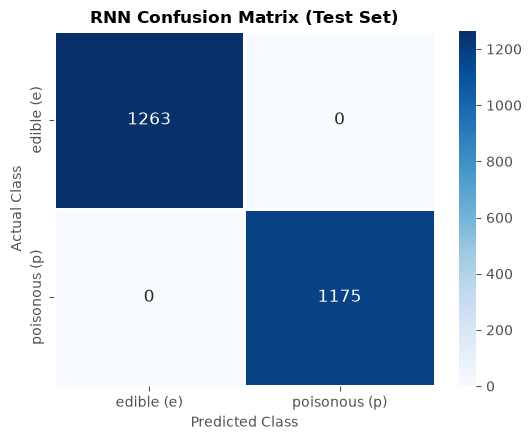

Rows = actual class, columns = predicted class
                       Predicted: edible (e)  Predicted: poisonous (p)
Actual: edible (e)                      1263                         0
Actual: poisonous (p)                      0                      1175


In [28]:
rnn_cm = plot_confusion_matrix(y_test, rnn_pred, "RNN", "rnn_confusion_matrix.png")
print("Rows = actual class, columns = predicted class")
print(pd.DataFrame(rnn_cm, index=[f"Actual: {c}" for c in CLASS_LABELS],
                   columns=[f"Predicted: {c}" for c in CLASS_LABELS]))

## 19. RNN Classification Report

In [29]:
rnn_report = save_classification_report(y_test, rnn_pred, "RNN", "rnn")

RNN Classification Report (Test Set)

               precision    recall  f1-score   support

   edible (e)     1.0000    1.0000    1.0000      1263
poisonous (p)     1.0000    1.0000    1.0000      1175

     accuracy                         1.0000      2438
    macro avg     1.0000    1.0000    1.0000      2438
 weighted avg     1.0000    1.0000    1.0000      2438



## 20. CNN vs RNN Comparison

The table and chart below compare both models using their **measured** test accuracy.

In [30]:
comparison = pd.DataFrame({
    "Model":            ["CNN", "RNN"],
    "Optimizer":        ["Adam", "RMSprop"],
    "Batch Size":       [CNN_BATCH_SIZE, RNN_BATCH_SIZE],
    "Epochs":           [CNN_EPOCHS, RNN_EPOCHS],
    "Test Accuracy":    [round(cnn_test_accuracy, 4), round(rnn_test_accuracy, 4)],
    "Test Loss":        [round(cnn_test_loss, 4), round(rnn_test_loss, 4)],
    "Macro F1-score":   [round(cnn_report["macro avg"]["f1-score"], 4), round(rnn_report["macro avg"]["f1-score"], 4)],
    "Training Time (s)": [round(cnn_training_time, 1), round(rnn_training_time, 1)],
})
comparison.to_csv(REPORTS_DIR / "cnn_vs_rnn_comparison.csv", index=False)
display(comparison)
print("Comparison table saved to outputs/reports/cnn_vs_rnn_comparison.csv")

,Model,Optimizer,Batch Size,Epochs,Test Accuracy,Test Loss,Macro F1-score,Training Time (s)
0,CNN,Adam,30,10,1.0,0.0002,1.0,9.2
1,RNN,RMSprop,40,20,1.0,0.0000,1.0,30.1


Comparison table saved to outputs/reports/cnn_vs_rnn_comparison.csv


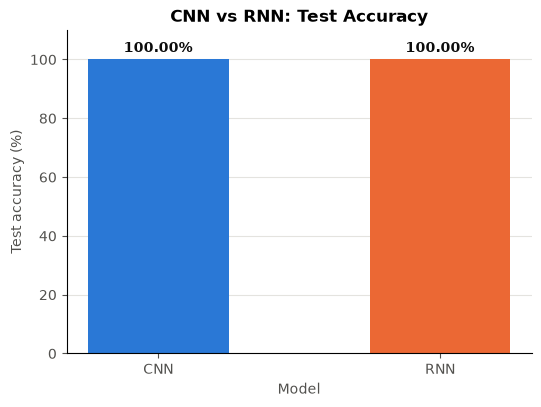

In [31]:
accuracies = [cnn_test_accuracy, rnn_test_accuracy]
fig, ax = plt.subplots(figsize=(6, 4.2))
bars = ax.bar(["CNN", "RNN"], [a * 100 for a in accuracies], color=[COLOR_1, COLOR_2], width=0.5)
ax.bar_label(bars, labels=[f"{a:.2%}" for a in accuracies], padding=3, color="#0b0b0b", fontweight="bold")
ax.set_title("CNN vs RNN: Test Accuracy")
ax.set_xlabel("Model")
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 110)
ax.grid(axis="x", visible=False)
plt.savefig(FIGURES_DIR / "cnn_vs_rnn_accuracy.png")
plt.show()

## 21. Final Recommendation

The recommendation is computed from the measured test accuracies.
If the two accuracies are equal, the model with the shorter training time is preferred.

In [32]:
SMALL_DIFFERENCE = 0.005   # 0.5 percentage points
difference = cnn_test_accuracy - rnn_test_accuracy

if difference > 0:
    recommended = "CNN"
elif difference < 0:
    recommended = "RNN"
else:
    recommended = "CNN" if cnn_training_time <= rnn_training_time else "RNN"

print(f"CNN test accuracy: {cnn_test_accuracy:.4f} ({cnn_test_accuracy:.2%})")
print(f"RNN test accuracy: {rnn_test_accuracy:.4f} ({rnn_test_accuracy:.2%})")
print(f"Difference       : {abs(difference) * 100:.2f} percentage points")
print()
print(f"Based on the test accuracy, the recommended model is {recommended}.")

if difference == 0:
    print("Both models reached exactly the same test accuracy, so the model with the shorter "
          f"training time ({recommended}) is recommended.")
elif abs(difference) < SMALL_DIFFERENCE:
    print(f"Note: the difference is extremely small (less than {SMALL_DIFFERENCE * 100:.1f} percentage points), "
          "so both models perform almost equally well on this dataset.")

print()
if difference == 0:
    print(f"Interpretation: The CNN and the RNN both achieved {cnn_test_accuracy:.2%} test accuracy, so they "
          f"classify this dataset equally well. The {recommended} is preferred because it trained faster "
          f"({min(cnn_training_time, rnn_training_time):.1f}s vs {max(cnn_training_time, rnn_training_time):.1f}s).")
else:
    print(f"Interpretation: The CNN achieved {cnn_test_accuracy:.2%} test accuracy, while the RNN achieved "
          f"{rnn_test_accuracy:.2%} test accuracy. Therefore, the {recommended}, which has the higher test accuracy, "
          "provides better classification performance on this dataset.")

CNN test accuracy: 1.0000 (100.00%)
RNN test accuracy: 1.0000 (100.00%)
Difference       : 0.00 percentage points

Based on the test accuracy, the recommended model is CNN.
Both models reached exactly the same test accuracy, so the model with the shorter training time (CNN) is recommended.

Interpretation: The CNN and the RNN both achieved 100.00% test accuracy, so they classify this dataset equally well. The CNN is preferred because it trained faster (9.2s vs 30.1s).


### Why can the accuracy be so high?

To understand the results, we check how well **each single feature on its own** separates the classes.
For every feature we predict the most common class for each of its categories, using the
**training data only**, and measure the accuracy of that simple rule.

In [33]:
single_feature_rules = []
for col in X_train_raw.columns:
    majority_class = y_train_raw.groupby(X_train_raw[col]).agg(lambda s: s.mode()[0])
    rule_accuracy = (X_train_raw[col].map(majority_class) == y_train_raw).mean()
    single_feature_rules.append((col, X_train_raw[col].nunique(), rule_accuracy))

single_feature_rules = (pd.DataFrame(single_feature_rules,
                                     columns=["Feature", "Categories", "Single-feature rule accuracy (train)"])
                        .sort_values("Single-feature rule accuracy (train)", ascending=False)
                        .reset_index(drop=True))
display(single_feature_rules.head(5).round(4))

best = single_feature_rules.iloc[0]
print(f"The single most informative feature is '{best['Feature']}': on its own it classifies "
      f"{best['Single-feature rule accuracy (train)']:.2%} of the training mushrooms correctly.")
print("Combining all features lets the neural networks learn the remaining cases, which explains why "
      "both models can reach very high test accuracy on this dataset.")

,Feature,Categories,Single-feature rule accuracy (train)
0,odor,9,0.9845
1,spore-print-color,9,0.8677
2,gill-color,12,0.8032
3,stalk-surface-above-ring,4,0.7745
4,ring-type,5,0.7712


The single most informative feature is 'odor': on its own it classifies 98.45% of the training mushrooms correctly.
Combining all features lets the neural networks learn the remaining cases, which explains why both models can reach very high test accuracy on this dataset.


## 22. Generative AI / NLP Task

Modern Large Language Models (LLMs) such as BERT and GPT cannot read raw text directly.
Text is first split into **tokens** (words or sub-word pieces) by a **tokenizer**, and each token is
mapped to an integer **input ID** from the model's vocabulary. This step is called **tokenization**.

In this task we use the pretrained **`bert-base-uncased`** tokenizer from Hugging Face Transformers.
No language model is trained; only tokenization is performed.

## 23. Load `exercise_text.json`

The JSON structure is inspected first instead of being assumed. All text values are then extracted
recursively, so the code works whether the text is stored as a single string, a list or nested objects.

In [34]:
with open(TEXT_JSON, "r", encoding="utf-8-sig") as f:
    text_data = json.load(f)

def describe_structure(obj, indent=0, max_items=5):
    """Print the shape of a JSON object (types and keys) without printing all the content."""
    pad = "    " * indent
    if isinstance(obj, dict):
        print(f"{pad}dict with {len(obj)} key(s): {list(obj.keys())}")
        for key, value in list(obj.items())[:max_items]:
            print(f"{pad}  '{key}':")
            describe_structure(value, indent + 1, max_items)
    elif isinstance(obj, list):
        print(f"{pad}list with {len(obj)} item(s)")
        for item in obj[:max_items]:
            describe_structure(item, indent + 1, max_items)
    else:
        preview = str(obj)
        preview = preview[:60] + "..." if len(preview) > 60 else preview
        print(f"{pad}{type(obj).__name__}: {preview!r}")

print("JSON structure:")
describe_structure(text_data)

JSON structure:
dict with 1 key(s): ['text']
  'text':
    str: 'In this exercise, you are required to Apply and evaluate CNN...'


In [35]:
TEXT_KEYS = ("text", "content", "body", "sentence", "paragraph", "description")

def extract_texts(obj):
    """Recursively collect text strings from a JSON object.
    Values stored under common text keys are preferred; otherwise all strings are collected."""
    preferred, others = [], []

    def walk(node, key=None):
        if isinstance(node, dict):
            for k, v in node.items():
                walk(v, k)
        elif isinstance(node, list):
            for item in node:
                walk(item, key)
        elif isinstance(node, str) and node.strip():
            (preferred if key and key.lower() in TEXT_KEYS else others).append(node.strip())

    walk(obj)
    return preferred or others

texts = extract_texts(text_data)
if not texts:
    raise ValueError("No text could be found in exercise_text.json")

original_text = "\n".join(texts)
print(f"Number of text passages found: {len(texts)}")
print(f"Characters: {len(original_text):,}  |  Words: {len(original_text.split()):,}")
print("\nOriginal text:\n")
print(original_text)

Number of text passages found: 1
Characters: 840  |  Words: 123

Original text:

In this exercise, you are required to Apply and evaluate CNN, ANN, and RNN models Compare their performance and identify the model that achieves the highest accuracy for image classification using the **Iris Flowers dataset**. You will load and preprocess image data, design a multi-layer CNN architecture using TensorFlow/Keras, and train the model to recognize different object categories. After training, you will evaluate the model's performance on unseen test data and visualize the training loss across epochs. The objective of this exercise is to provide hands-on experience with **Deep Learning and Computer Vision**, enabling you to understand the complete workflow of an image classification project. Also solve the Large Language Models (LLMs) Architecture & Work. And Using LLMs with LangChain, passing prompts programmatically.


## 24. Hugging Face Tokenization

The tokenizer is loaded with `AutoTokenizer.from_pretrained("bert-base-uncased")`
(it is downloaded from the Hugging Face Hub the first time).

* **Truncation** is enabled at BERT's 512-token limit, so longer text would be cut safely.
* **Padding** is *not* used, because we tokenize a single text and padding is only needed to make
  several texts the same length in a batch.
* BERT automatically adds the special tokens `[CLS]` (start) and `[SEP]` (end).

In [36]:
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging

hf_logging.set_verbosity_error()    # hide non-critical Hugging Face warnings
hub_logging.set_verbosity_error()

TOKENIZER_NAME = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
print("Tokenizer loaded :", TOKENIZER_NAME)
print("Vocabulary size  :", f"{tokenizer.vocab_size:,}")
print("Max input length :", tokenizer.model_max_length)

Tokenizer loaded : bert-base-uncased
Vocabulary size  : 30,522
Max input length : 512


In [37]:
encoded = tokenizer(original_text, truncation=True, max_length=tokenizer.model_max_length)

tokens         = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
input_ids      = encoded["input_ids"]
attention_mask = encoded["attention_mask"]

print("Tokenized output (keys returned by the tokenizer):", list(encoded.keys()))
print()
print("Tokens:")
print(tokens)
print()
print("Input IDs:")
print(input_ids)
print()
print("Attention mask:")
print(attention_mask)
print()
print("Number of tokens (including [CLS] and [SEP]):", len(input_ids))
print("Number of tokens (excluding special tokens) :", len(tokenizer.tokenize(original_text)))
print("Truncated?", len(tokenizer(original_text)["input_ids"]) > tokenizer.model_max_length)

Tokenized output (keys returned by the tokenizer): ['input_ids', 'token_type_ids', 'attention_mask']

Tokens:
['[CLS]', 'in', 'this', 'exercise', ',', 'you', 'are', 'required', 'to', 'apply', 'and', 'evaluate', 'cnn', ',', 'ann', ',', 'and', 'rn', '##n', 'models', 'compare', 'their', 'performance', 'and', 'identify', 'the', 'model', 'that', 'achieve', '##s', 'the', 'highest', 'accuracy', 'for', 'image', 'classification', 'using', 'the', '*', '*', 'iris', 'flowers', 'data', '##set', '*', '*', '.', 'you', 'will', 'load', 'and', 'prep', '##ro', '##ces', '##s', 'image', 'data', ',', 'design', 'a', 'multi', '-', 'layer', 'cnn', 'architecture', 'using', 'tensor', '##flow', '/', 'ke', '##ras', ',', 'and', 'train', 'the', 'model', 'to', 'recognize', 'different', 'object', 'categories', '.', 'after', 'training', ',', 'you', 'will', 'evaluate', 'the', 'model', "'", 's', 'performance', 'on', 'unseen', 'test', 'data', 'and', 'visual', '##ize', 'the', 'training', 'loss', 'across', 'epoch', '##s', '

In [38]:
# Token-by-token view of the first 25 tokens
token_table = pd.DataFrame({
    "Token": tokens,
    "Input ID": input_ids,
    "Attention Mask": attention_mask,
})
token_table.to_csv(REPORTS_DIR / "tokenization_output.csv", index_label="position")
print("First 25 tokens (full table saved to outputs/reports/tokenization_output.csv):")
display(token_table.head(25))

First 25 tokens (full table saved to outputs/reports/tokenization_output.csv):


,Token,Input ID,Attention Mask
0,[CLS],101,1
1,in,1999,1
2,this,2023,1
3,exercise,6912,1
4,",",1010,1
5,you,2017,1
6,are,2024,1
7,required,3223,1
8,to,2000,1
9,apply,6611,1


In [39]:
# Decoding the input IDs back to text confirms that tokenization is reversible
decoded_text = tokenizer.decode(input_ids, skip_special_tokens=True)
print("Decoded text (lower-cased by the 'uncased' tokenizer):\n")
print(decoded_text)

subword_tokens = [t for t in tokens if t.startswith("##")]
print(f"\nSub-word pieces (start with '##'): {len(subword_tokens)} -> {subword_tokens}")

Decoded text (lower-cased by the 'uncased' tokenizer):

in this exercise, you are required to apply and evaluate cnn, ann, and rnn models compare their performance and identify the model that achieves the highest accuracy for image classification using the * * iris flowers dataset * *. you will load and preprocess image data, design a multi - layer cnn architecture using tensorflow / keras, and train the model to recognize different object categories. after training, you will evaluate the model ' s performance on unseen test data and visualize the training loss across epochs. the objective of this exercise is to provide hands - on experience with * * deep learning and computer vision * *, enabling you to understand the complete workflow of an image classification project. also solve the large language models ( llms ) architecture & work. and using llms with langchain, passing prompts programmatically.

Sub-word pieces (start with '##'): 18 -> ['##n', '##s', '##set', '##ro', '##ces', '#

**Interpretation:** The tokenizer lower-cases the text and splits it into word and sub-word tokens.
Words missing from BERT's vocabulary are broken into pieces marked with `##`. Each token has an
integer **input ID**. The **attention mask** is `1` for every real token; it would be `0` only for
padding tokens, and no padding was used here.

## 25. Final Summary

In [40]:
print("=" * 70)
print("FINAL SUMMARY")
print("=" * 70)
print(f"Dataset              : {MUSHROOM_CSV.name} - {df.shape[0]:,} samples, {df.shape[1] - 1} categorical features")
print(f"Target column        : '{TARGET_COL}' with {NUM_CLASSES} classes: {', '.join(CLASS_LABELS)}")
print(f"Encoded features     : {NUM_FEATURES} one-hot columns -> input shape ({NUM_FEATURES}, 1)")
print(f"Train / test split   : {len(X_train):,} / {len(X_test):,} samples (70% / 30%, random_state={RANDOM_STATE})")
print()
display(comparison[["Model", "Optimizer", "Batch Size", "Epochs", "Test Accuracy"]])
print(f"Recommended model    : {recommended}")
print()
print(f"NLP task             : '{TEXT_JSON.name}' tokenized with {TOKENIZER_NAME} -> {len(input_ids)} tokens")
print()
print("Saved figures:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print("  -", path.relative_to(PROJECT_ROOT))
print("Saved reports:")
for path in sorted(REPORTS_DIR.glob("*")):
    print("  -", path.relative_to(PROJECT_ROOT))
print("Saved models:")
for path in sorted(MODELS_DIR.glob("*.keras")):
    print("  -", path.relative_to(PROJECT_ROOT))

FINAL SUMMARY
Dataset              : mushrooms.csv - 8,124 samples, 22 categorical features
Target column        : 'class' with 2 classes: edible (e), poisonous (p)
Encoded features     : 116 one-hot columns -> input shape (116, 1)
Train / test split   : 5,686 / 2,438 samples (70% / 30%, random_state=42)



,Model,Optimizer,Batch Size,Epochs,Test Accuracy
0,CNN,Adam,30,10,1.0
1,RNN,RMSprop,40,20,1.0


Recommended model    : CNN

NLP task             : 'exercise_text.json' tokenized with bert-base-uncased -> 175 tokens

Saved figures:
  - outputs\figures\class_distribution.png
  - outputs\figures\cnn_confusion_matrix.png
  - outputs\figures\cnn_training_history.png
  - outputs\figures\cnn_vs_rnn_accuracy.png
  - outputs\figures\rnn_confusion_matrix.png
  - outputs\figures\rnn_training_history.png
Saved reports:
  - outputs\reports\cnn_classification_report.csv
  - outputs\reports\cnn_classification_report.txt
  - outputs\reports\cnn_vs_rnn_comparison.csv
  - outputs\reports\rnn_classification_report.csv
  - outputs\reports\rnn_classification_report.txt
  - outputs\reports\test_predictions_cnn_rnn.csv
  - outputs\reports\tokenization_output.csv
Saved models:
  - outputs\models\cnn_model.keras
  - outputs\models\rnn_model.keras


### Conclusions

* The categorical mushroom features were one-hot encoded (fitted on training data only) and reshaped
  to `(samples, features, 1)` so they could be used by both a **Conv1D CNN** and a **SimpleRNN**.
* Both models were trained with the required settings (CNN: Adam, batch 30, 10 epochs; RNN: RMSprop,
  batch 40, 20 epochs) and evaluated on the same unseen 30% test set.
* The comparison table, bar chart and recommendation above are generated from the measured results.
* For the Generative AI task, the text from `exercise_text.json` was tokenized with the pretrained
  `bert-base-uncased` tokenizer, showing the tokens, input IDs and attention mask that an LLM receives.

> **Reproducibility note:** Random seeds are fixed to 42, but neural-network results can still vary slightly
> depending on hardware (CPU/GPU), operating system and TensorFlow version.